Risk report of one stock, run for each stock by 03_run_all_stocks.py with papermill.

In [1]:
# Parameters
ticker = "AAPL"  # Stock ticker to analyze
start_date = "2024-01-01"  # Analysis start date
end_date = "2024-12-31"  # Analysis end date
db_path = "data/data.db"  # Database that contains ohlc_hw_cleaned

In [2]:
import os
import sqlite3

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scrapbook as sb
from IPython.display import display

%matplotlib inline
plt.style.use("seaborn-v0_8-whitegrid")

Step 1: Load the data

I stop with a clear error if there are less than 21 prices (a 20-day volatility needs 20 returns), so the batch records the stock as failed.

In [3]:
if not os.path.exists(db_path):
    raise FileNotFoundError(f"{db_path} not found: run 01_data_cleaning.ipynb first.")
if pd.Timestamp(start_date) > pd.Timestamp(end_date):
    raise ValueError("start_date must be before end_date.")

conn = sqlite3.connect(db_path)
query = """
SELECT ts, open, high, low, close, adj_close, volume, extreme_return_flag
FROM ohlc_hw_cleaned
WHERE ticker = ? AND ts >= ? AND ts <= ?
ORDER BY ts
"""
df = pd.read_sql_query(query, conn, params=(ticker, start_date, end_date), parse_dates=["ts"], index_col="ts")
conn.close()

if len(df) == 0:
    raise ValueError(f"No data for {ticker} between {start_date} and {end_date}.")
if len(df) < 21:
    raise ValueError(f"{ticker}: only {len(df)} prices between {start_date} and {end_date}. "
                     "A 20-day volatility needs at least 21 prices.")

print(f"{ticker} from {start_date} to {end_date}: {len(df)} trading days")
print(f"First and last date in the data: {df.index[0].date()} to {df.index[-1].date()}")
display(df.head())
display(df.tail())

AAPL from 2024-01-01 to 2024-12-31: 202 trading days
First and last date in the data: 2024-01-02 to 2024-10-18


,open,high,low,close,adj_close,volume,extreme_return_flag
ts,,,,,,,
2024-01-02,187.15,188.44,183.89,185.64,184.94,82488674,0
2024-01-03,184.22,185.88,183.43,184.25,183.55,58414460,0
2024-01-04,182.15,183.09,180.88,181.91,181.22,71983570,0
2024-01-05,181.99,182.76,180.17,181.18,180.50,62379661,0
2024-01-08,182.09,185.60,181.50,185.56,184.86,59144470,0


,open,high,low,close,adj_close,volume,extreme_return_flag
ts,,,,,,,
2024-10-14,228.70,231.73,228.60,231.30,231.30,39882100,0
2024-10-15,233.61,237.49,232.37,233.85,233.85,64751400,0
2024-10-16,231.60,232.12,229.84,231.78,231.78,34082240,0
2024-10-17,233.43,233.85,230.52,232.15,232.15,32993810,0
2024-10-18,236.18,236.18,234.01,235.00,235.00,45441281,0


22 stocks have no data after 2024-10-18, so I print the real first and last date. The metrics use only these dates, I do not extend the prices.

In [4]:
assert np.isfinite(df[["open", "high", "low", "close", "adj_close", "volume"]]).all().all()
assert (df[["open", "high", "low", "close", "adj_close"]] > 0).all().all()
assert ((df["low"] <= df["close"]) & (df["close"] <= df["high"])).all()
assert not df.index.duplicated().any()
flagged = df.index[df["extreme_return_flag"] == 1]
print("Data checks passed. Days flagged as very large returns in the cleaning (kept, to verify):",
      [d.date().isoformat() for d in flagged] or "none")

Data checks passed. Days flagged as very large returns in the cleaning (kept, to verify): none


Step 2: Risk metrics

In [5]:
def calculate_returns(prices: pd.Series) -> pd.Series:
    """Calculate daily log returns: ln(P_t / P_t-1). The first value is NaN (no day before)."""
    return np.log(prices / prices.shift(1))


def calculate_volatility(returns: pd.Series, window: int = 20) -> pd.Series:
    """Calculate annualized rolling volatility: rolling std of the daily log returns * sqrt(252).

    The first `window` values are NaN (not enough returns yet). We do not replace them by 0.
    """
    return returns.rolling(window).std() * np.sqrt(252)


def calculate_max_drawdown(prices: pd.Series) -> pd.Series:
    """Return per-date drawdown: (price - highest price so far) / highest price so far.

    The maximum drawdown of the period is the minimum of this series.
    """
    peak = prices.cummax()
    return (prices - peak) / peak


def calculate_sharpe_ratio(returns: pd.Series, risk_free_rate: float = 0.02) -> float:
    """Calculate annualized Sharpe ratio: (mean * 252 - rf) / (std * sqrt(252)).

    Returns NaN when we cannot compute it (less than 2 returns, or a volatility of 0).
    """
    returns = returns.dropna()
    if len(returns) < 2 or returns.std() == 0:
        return np.nan
    return (returns.mean() * 252 - risk_free_rate) / (returns.std() * np.sqrt(252))


# small checks that we can verify by hand
assert np.isclose(calculate_returns(pd.Series([100.0, 110.0])).iloc[1], np.log(1.1))
assert np.allclose(calculate_max_drawdown(pd.Series([80.0, 100.0, 70.0, 85.0])), [0, 0, -0.30, -0.15])
assert np.isnan(calculate_sharpe_ratio(pd.Series([0.01, 0.01, 0.01])))

In [6]:
df["log_return"] = calculate_returns(df["adj_close"])
df["volatility"] = calculate_volatility(df["log_return"])
df["drawdown"] = calculate_max_drawdown(df["adj_close"])
df["ma_50"] = df["adj_close"].rolling(50).mean()

returns = df["log_return"].dropna()
n = len(returns)
total_return = df["adj_close"].iloc[-1] / df["adj_close"].iloc[0] - 1
annualized_return = np.exp(returns.sum() * 252 / n) - 1
annualized_volatility = returns.std() * np.sqrt(252)
sharpe_ratio = calculate_sharpe_ratio(returns)
max_drawdown = df["drawdown"].min()
mean_volatility = df["volatility"].mean()

display(df[["adj_close", "log_return", "volatility", "drawdown"]].iloc[18:23])

,adj_close,log_return,volatility,drawdown
ts,,,,
2024-01-29,191.01,-0.003554,NaN,-0.017640
2024-01-30,187.33,-0.019454,NaN,-0.036567
2024-01-31,183.70,-0.019568,0.211168,-0.055236
2024-02-01,186.15,0.013249,0.214625,-0.042635
2024-02-02,185.15,-0.005386,0.210024,-0.047778


Step 3: Charts

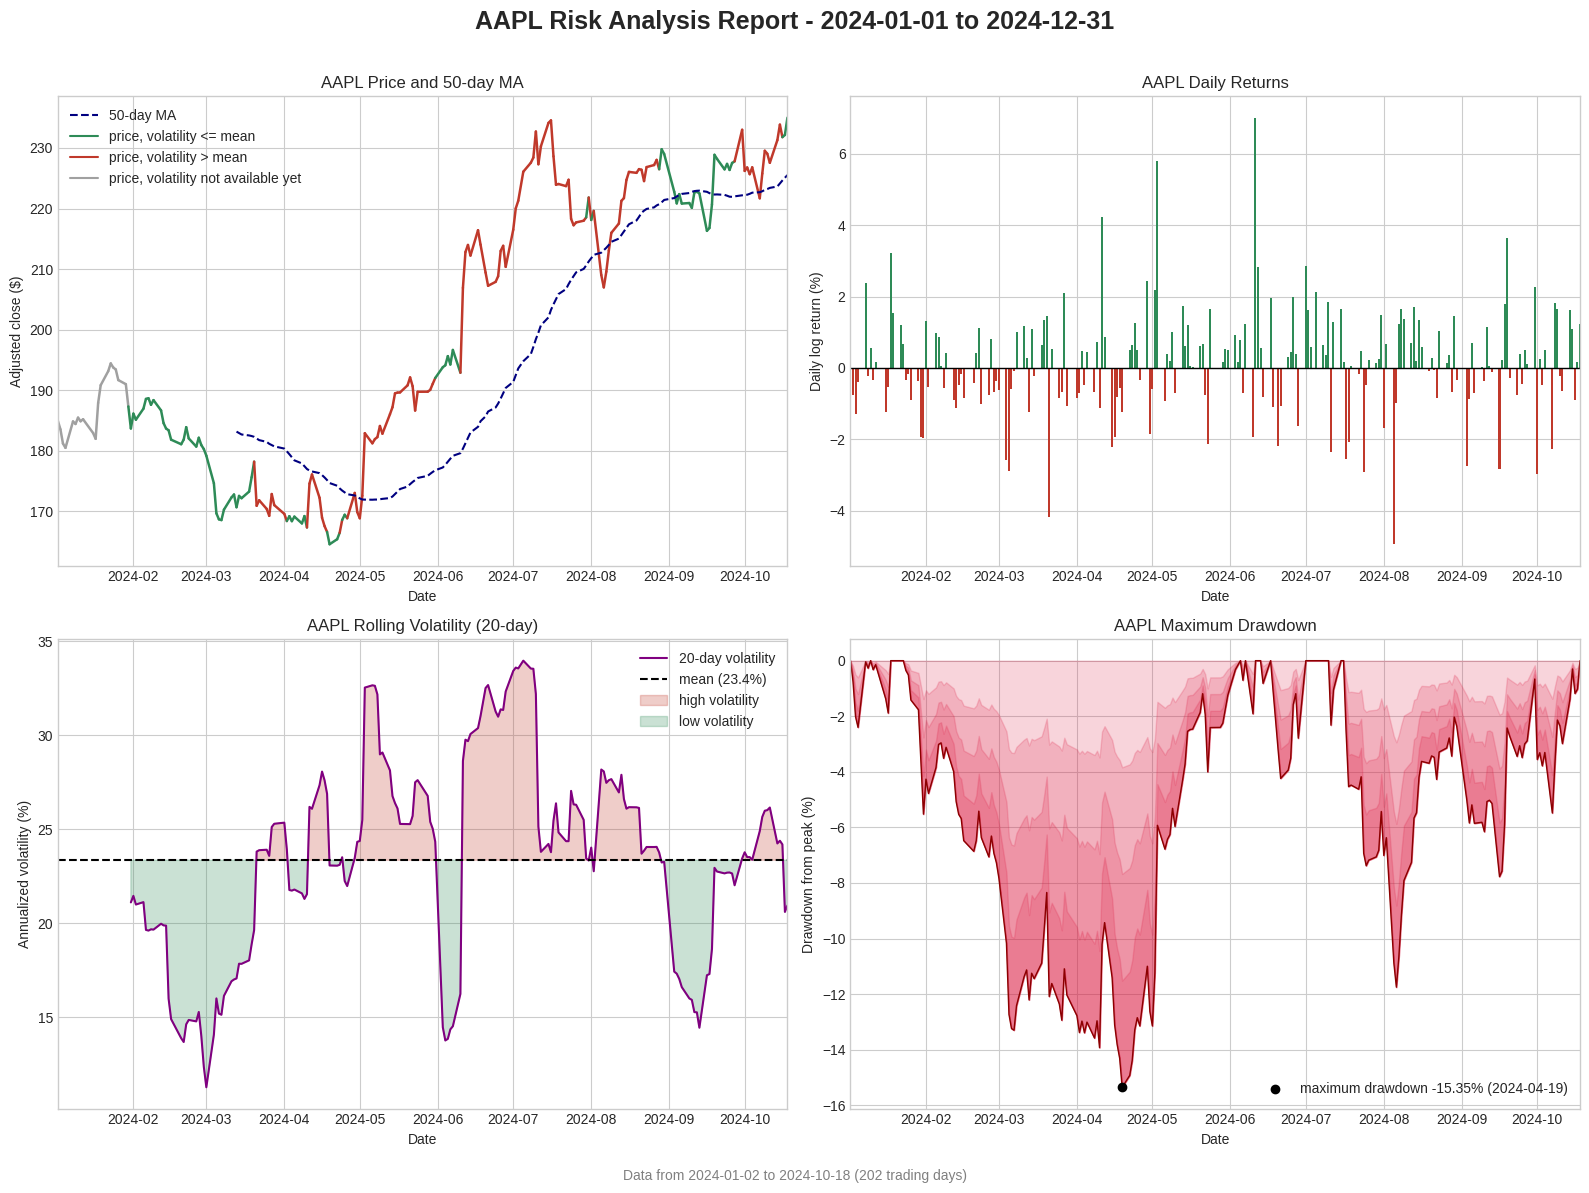

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle(f"{ticker} Risk Analysis Report - {start_date} to {end_date}", fontsize=18, fontweight="bold")
fig.text(0.5, 0.005, f"Data from {df.index[0].date()} to {df.index[-1].date()} ({len(df)} trading days)",
         ha="center", color="gray")
green, red, gray = "#2e8b57", "#c0392b", "#a0a0a0"

# top left: price (color = volatility) and 50-day moving average
ax = axes[0, 0]
for i in range(1, len(df)):
    vol = df["volatility"].iloc[i]
    color = gray if np.isnan(vol) else (red if vol > mean_volatility else green)
    ax.plot(df.index[i - 1:i + 1], df["adj_close"].iloc[i - 1:i + 1], color=color, linewidth=1.8)
ax.plot(df.index, df["ma_50"], color="navy", linestyle="--", label="50-day MA")
if df["ma_50"].isna().all():
    ax.text(0.02, 0.05, "50-day MA not available: less than 50 prices", transform=ax.transAxes)
ax.plot([], [], color=green, label="price, volatility <= mean")
ax.plot([], [], color=red, label="price, volatility > mean")
ax.plot([], [], color=gray, label="price, volatility not available yet")
ax.legend()
ax.set(title=f"{ticker} Price and 50-day MA", xlabel="Date", ylabel="Adjusted close ($)")

# top right: daily returns
ax = axes[0, 1]
ax.bar(df.index, df["log_return"] * 100, color=np.where(df["log_return"] >= 0, green, red))
ax.axhline(0, color="black", linewidth=1)
ax.set(title=f"{ticker} Daily Returns", xlabel="Date", ylabel="Daily log return (%)")

# bottom left: 20-day volatility and its mean
ax = axes[1, 0]
vol_pct = df["volatility"] * 100
ax.plot(df.index, vol_pct, color="purple", label="20-day volatility")
ax.axhline(mean_volatility * 100, color="black", linestyle="--", label=f"mean ({mean_volatility:.1%})")
ax.fill_between(df.index, vol_pct, mean_volatility * 100, where=vol_pct > mean_volatility * 100,
                color=red, alpha=0.25, interpolate=True, label="high volatility")
ax.fill_between(df.index, vol_pct, mean_volatility * 100, where=vol_pct <= mean_volatility * 100,
                color=green, alpha=0.25, interpolate=True, label="low volatility")
ax.legend()
ax.set(title=f"{ticker} Rolling Volatility (20-day)", xlabel="Date", ylabel="Annualized volatility (%)")

# bottom right: drawdown and maximum drawdown
ax = axes[1, 1]
dd_pct = df["drawdown"] * 100
for share in [0, 0.25, 0.5, 0.75]:             # 4 layers: darker red when the fall is deeper
    ax.fill_between(df.index, dd_pct, dd_pct * share, color="crimson", alpha=0.18)
ax.plot(df.index, dd_pct, color="darkred", linewidth=1)
worst_day = df["drawdown"].idxmin()
ax.scatter([worst_day], [max_drawdown * 100], color="black", zorder=3,
           label=f"maximum drawdown {max_drawdown:.2%} ({worst_day.date()})")
ax.legend(loc="best")
ax.set(title=f"{ticker} Maximum Drawdown", xlabel="Date", ylabel="Drawdown from peak (%)")

for ax in axes.flat:
    ax.grid(True)
    ax.set_xlim(df.index[0], df.index[-1])
plt.tight_layout(rect=(0, 0.02, 1, 0.97))
plt.show()

Price colors: red when the 20-day volatility is above its mean on the period, green below, gray for the first 20 days (no volatility yet).

Step 4: Summary statistics

Annualized return = exp(sum of the log returns * 252 / n) - 1, to stay consistent with the log returns. Annualized volatility uses all the daily returns of the period, it is not the mean of the 20-day volatility. Positive days counts the days at 0 in the total.

In [8]:
up, down = returns[returns > 0], returns[returns < 0]
summary = {
    "Total Return": total_return,
    "Annualized Return": annualized_return,
    "Annualized Volatility": annualized_volatility,
    "Sharpe Ratio": sharpe_ratio,
    "Maximum Drawdown": max_drawdown,
    "Best Day": returns.max(),
    "Worst Day": returns.min(),
    "Positive Days": (returns > 0).sum() / n,
    "Average Up Day": up.mean() if len(up) > 0 else np.nan,
    "Average Down Day": down.mean() if len(down) > 0 else np.nan,
}


def show(name, value):
    """Format a metric for the display only. In the calculations, the values stay as fractions (0.05 = 5%)."""
    if pd.isna(value):
        return "N/A"
    if name == "Sharpe Ratio":
        return f"{value:.2f}"
    if name in ["Annualized Volatility", "Positive Days"]:
        return f"{value:.2%}"
    return f"{value:+.2%}"


print(f"{'Metric':<24} {'Value':>8}")
print(f"{'-' * 24} {'-' * 8}")
for name, value in summary.items():
    print(f"{name:<24} {show(name, value):>8}")

Metric                      Value
------------------------ --------
Total Return              +27.07%
Annualized Return         +35.03%
Annualized Volatility      23.61%
Sharpe Ratio                 1.19
Maximum Drawdown          -15.35%
Best Day                   +7.01%
Worst Day                  -4.94%
Positive Days              55.72%
Average Up Day             +1.08%
Average Down Day           -1.09%


Step 5: Save the results

In [9]:
sb.glue("ticker", ticker)
sb.glue("first_obs", df.index[0].strftime("%Y-%m-%d"))
sb.glue("last_obs", df.index[-1].strftime("%Y-%m-%d"))
sb.glue("trading_days", len(df))
sb.glue("avg_daily_return", float(returns.mean()))
sb.glue("avg_volatility", float(mean_volatility))
sb.glue("max_drawdown", float(max_drawdown))
sb.glue("sharpe_ratio", float(sharpe_ratio))
sb.glue("total_return", float(total_return))